In [2]:
!pip install xgboost

In [4]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, classification_report

In [5]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", np.unique(y))
print(X.head())

Dataset shape: (569, 30)
Target classes: [0 1]
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius 

In [6]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (455, 30)
Test set shape: (114, 30)


In [7]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Random Forest trained successfully!
Gradient Boosting trained successfully!
XGBoost trained successfully!


In [8]:
results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)

print(results_df)

               Model  Accuracy
0      Random Forest     95.61
1  Gradient Boosting     95.61
2            XGBoost     94.74


In [9]:
rf_model = models["Random Forest"]
importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})
importances = importances.sort_values(by="Importance", ascending=False)
print(importances.head(10))

                 Feature  Importance
23            worst area    0.140016
27  worst concave points    0.129530
20          worst radius    0.097696
7    mean concave points    0.090885
22       worst perimeter    0.072226
2         mean perimeter    0.069574
0            mean radius    0.068676
6         mean concavity    0.057638
3              mean area    0.049172
26       worst concavity    0.034340


                 Feature  Importance
23            worst area    0.140016
27  worst concave points    0.129530
20          worst radius    0.097696
7    mean concave points    0.090885
22       worst perimeter    0.072226
2         mean perimeter    0.069574
0            mean radius    0.068676
6         mean concavity    0.057638
3              mean area    0.049172
26       worst concavity    0.034340


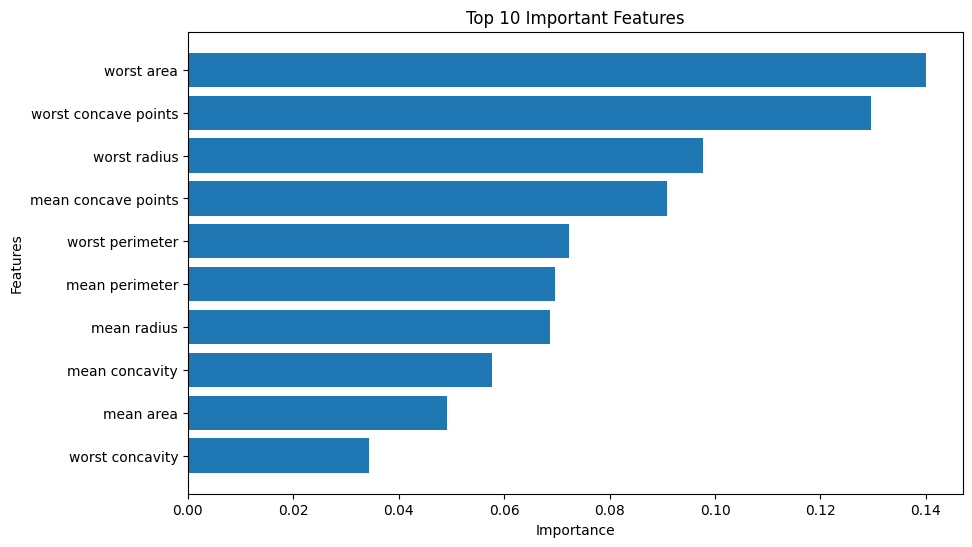

In [13]:
rf_model = models["Random Forest"]
importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})
importances = importances.sort_values(by="Importance", ascending=False)
print(importances.head(10))

import matplotlib.pyplot as plt

top_features = importances.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()
plt.show()

In [16]:
selected_features = importances.head(10)["Feature"].tolist()

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("Original features:", X_train.shape[1])
print("Selected features:", X_train_selected.shape[1])

rf_selected = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_selected.fit(X_train_selected, y_train)

predictions = rf_selected.predict(X_test_selected)

print("Accuracy with selected features:",
      accuracy_score(y_test, predictions) * 100)

Original features: 30
Selected features: 10
Accuracy with selected features: 95.6140350877193


In [17]:
!pip install imbalanced-learn


In [21]:
from imblearn.over_sampling import SMOTE
from collections import Counter
print("before smote",Counter(y_train))

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("After SMOTE:", Counter(y_train_smote))

smote_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

smote_model.fit(X_train_smote, y_train_smote)

smote_predictions = smote_model.predict(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, smote_predictions))


before smote Counter({np.int64(1): 285, np.int64(0): 170})
After SMOTE: Counter({np.int64(1): 285, np.int64(0): 285})
              precision    recall  f1-score   support

           0       0.91      0.95      0.93        42
           1       0.97      0.94      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



In [22]:
!pip install shap

SHAP explanation shape: (114, 30, 2)
X_test shape: (114, 30)
Final SHAP shape: (114, 30)


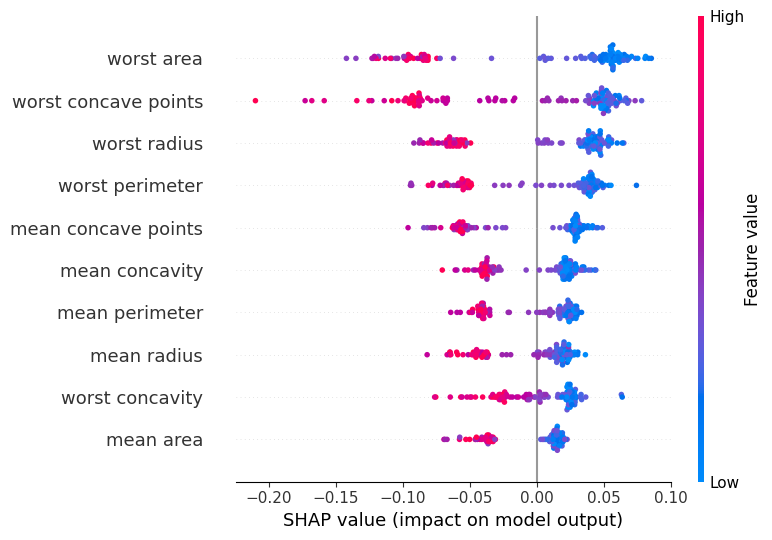

In [32]:
import shap
import numpy as np

# Create a fresh explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_exp = explainer(X_test)

print("SHAP explanation shape:", shap_exp.values.shape)
print("X_test shape:", X_test.shape)

values = shap_exp.values

if values.ndim == 3:
    if values.shape[1] == X_test.shape[1]:
        values = values[:, :, 1]
    elif values.shape[2] == X_test.shape[1]:
        values = values[:, 1, :]
    else:
        raise ValueError("Unexpected SHAP dimensions")

elif values.ndim != 2:
    raise ValueError("Unexpected SHAP output")

print("Final SHAP shape:", values.shape)

shap.summary_plot(
    values,
    X_test,
    max_display=10
)

